# 01 – Data exploration

Goal: understand the three datasets before building anything (size, labels, text length, duplicates, quality).

In [1]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

pd.set_option("display.max_colwidth", 200)

## 1. Resumes (`ahmedheakl/resume-atlas`)

In [2]:
resumes = load_dataset("ahmedheakl/resume-atlas")["train"].to_pandas()
print(resumes.shape)
resumes.head()

(13389, 2)


,Category,Text
0,Accountant,education omba executive leadership university texas 20162018 bachelor science accounting richland college 20052008 training certifications certified management accountant cma certified financial ...
1,Accountant,howard gerrard accountant deyjobcom birmingham 0123 456 7890 infodayjobcom linkedinname work experience company name accountant location summary howard considered expert managing companys finances...
2,Accountant,kevin frank senior accountant inforesumekraftcom 2025550120 chicago illinois us linkedincomresumekraft skills misrosoft office erp systems peach tree comsys leadership organizational skills docume...
3,Accountant,place birth nationality olivia ogilvy accountant 1515 pacific ave los angeles ca 90291 united states emailemailcom san antonio driving license american links twitter linkedin facebook profile empl...
4,Accountant,stephen greet cpa senior accountant 9 year experience establishing best accounting practices quickly growing tech companies ive learned value proractively identifying removing roadblocks allow acc...


43 categories, from 47 to 410 resumes each


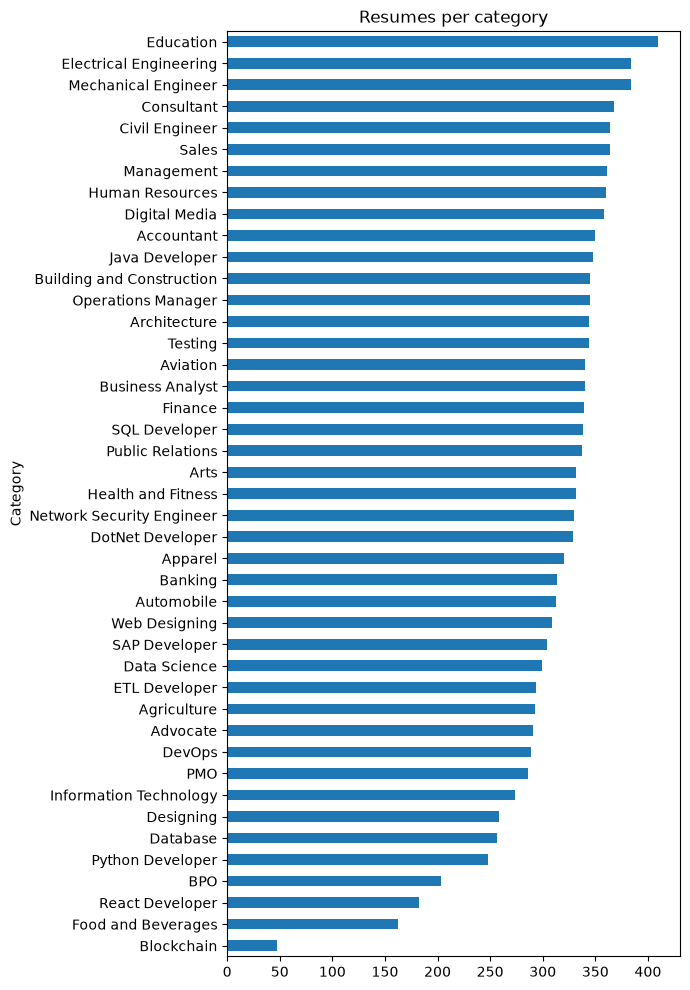

In [3]:
counts = resumes["Category"].value_counts()
print(f"{counts.size} categories, from {counts.min()} to {counts.max()} resumes each")
counts.sort_values().plot.barh(figsize=(7, 10), title="Resumes per category")
plt.tight_layout(); plt.show()

count    13389.0
mean       475.0
std        321.0
min          5.0
25%        240.0
50%        401.0
75%        615.0
max       6554.0
Name: n_words, dtype: float64


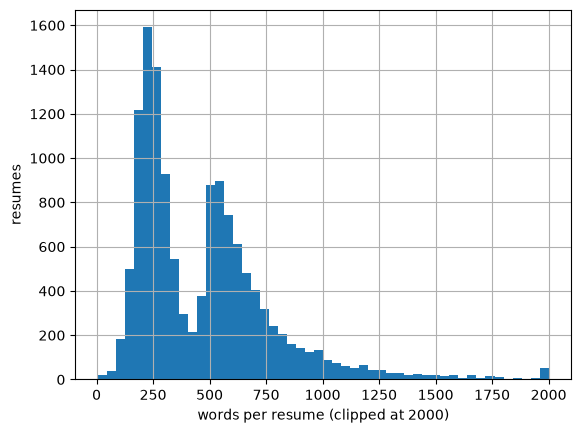

In [4]:
resumes["n_words"] = resumes["Text"].str.split().str.len()
print(resumes["n_words"].describe().round(0))
resumes["n_words"].clip(upper=2000).hist(bins=50)
plt.xlabel("words per resume (clipped at 2000)"); plt.ylabel("resumes"); plt.show()

In [5]:
# Quality checks
print("Empty or very short resumes (< 30 words):", (resumes["n_words"] < 30).sum())
print("Exact duplicate texts:", resumes["Text"].duplicated().sum())
print("Duplicates with a different category:",
      resumes[resumes["Text"].duplicated(keep=False)].groupby("Text")["Category"].nunique().gt(1).sum())

Empty or very short resumes (< 30 words): 15
Exact duplicate texts: 1304
Duplicates with a different category: 169


In [6]:
# The text is already preprocessed: lowercase, no punctuation, no line breaks.
# Consequence for the app: a resume pasted by a user must go through the same cleaning.
for cat in ["Data Science", "Human Resources", "Java Developer"]:
    print(cat, "->", resumes.loc[resumes["Category"] == cat, "Text"].iloc[0][:300], "\n")

Data Science -> diana dawa data scientist data scientist 4 years broadbased experience building dataintensive applications overcoming complex architectural scalability issues diverse industries proficient predictive modeling data processing data mining algorithms well scripting languages including python java capab 

Human Resources -> amelia quinton 9835 water street lake zurich il 60047 912 5553149 aquintonlivecom human resources trainer generalist specialist confident resourceful human resources professional academic background human resources management handson experience hiring training developing employees labor policies dis 

Java Developer -> java developer 123 address city state zip code xxxxxxxxxx youremailgmailcom technically advanced java developer 7 years experience designing developing delivering usercentric software applications using javaj2ee technologies offering strong expertise multiple programming languages including javascri 



## 2. Job descriptions (`jacob-hugging-face/job-descriptions`)

In [7]:
jobs = load_dataset("jacob-hugging-face/job-descriptions")["train"].to_pandas()
print(jobs.shape)
print(jobs["position_title"].value_counts().head(15))
jobs["job_description"].str.split().str.len().describe().round(0)

(853, 5)
position_title
Retail Sales Associate             9
Sales Associate                    9
Project Manager                    7
Inventory Clerk                    6
Systems Administrator              6
Web Developer                      5
Bank Teller                        5
Marketing Specialist               5
Data Entry Clerk                   5
Executive Assistant                5
Chief Executive Officer            4
Warehouse Manager                  4
Supply Chain Analyst               4
Customer Service Representative    4
Real Estate Agent                  4
Name: count, dtype: int64


count     853.0
mean      482.0
std       304.0
min         3.0
25%       281.0
50%       439.0
75%       629.0
max      3576.0
Name: job_description, dtype: float64

In [8]:
# `model_response` holds a structure extracted by an LLM (responsibilities, required skills...)
print(jobs.loc[0, "position_title"])
print(jobs.loc[0, "model_response"][:800])

Sales Specialist
 {
  "Core Responsibilities": "Responsible for expanding Google Workspace product adoption across an assigned territory. Build relationships with customers to understand needs and provide Google Workspace solutions. Partner with account teams to construct solutions and grow business for Google Workspace.",
  "Required Skills": "Bachelor's degree or equivalent experience. Experience managing enterprise SaaS accounts and sales cycles.", 
  "Educational Requirements": "Bachelor's degree or equivalent experience.",
  "Experience Level": "Experience managing enterprise SaaS accounts and sales cycles.",
  "Preferred Qualifications": "Experience building strategic partnerships with enterprise customers. Ability to work through a reseller ecosystem. Excellent communication and strategic thinking s


## 3. Data job postings (`lukebarousse/data_jobs`)

No description text, but a clean list of skills per posting: useful to build a skill vocabulary and to see the skills asked for each role.

In [9]:
data_jobs = load_dataset("lukebarousse/data_jobs")["train"].to_pandas()
print(data_jobs.shape)
print(data_jobs["job_title_short"].value_counts())
print("Postings without skills:", round(data_jobs["job_skills"].isna().mean() * 100, 1), "%")

(785741, 17)
job_title_short
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Business Analyst              49063
Software Engineer             44929
Senior Data Engineer          44563
Senior Data Scientist         36957
Senior Data Analyst           29216
Machine Learning Engineer     14080
Cloud Engineer                12331
Name: count, dtype: int64
Postings without skills: 14.9 %


In [10]:
skills = (data_jobs["job_skills"].dropna()
          .map(lambda s: ast.literal_eval(s) if isinstance(s, str) else list(s))
          .explode())
print(f"{skills.nunique()} distinct skills")
skills.value_counts().head(25)

252 distinct skills


job_skills
sql           384849
python        380909
aws           145381
azure         132527
r             130892
tableau       127213
excel         127018
spark         114609
power bi       98147
java           85612
sas            83404
hadoop         64842
scala          56886
snowflake      55015
databricks     53182
gcp            50727
git            50226
kafka          49926
airflow        45254
oracle         45221
nosql          45070
docker         41715
sql server     40197
go             38634
kubernetes     37349
Name: count, dtype: int64

In [11]:
# Top skills per role
dj = data_jobs.dropna(subset=["job_skills"]).copy()
dj["skill"] = dj["job_skills"].map(lambda s: ast.literal_eval(s) if isinstance(s, str) else list(s))
top = (dj.explode("skill").groupby("job_title_short")["skill"]
       .agg(lambda s: ", ".join(s.value_counts().head(8).index)))
top

job_title_short
Business Analyst              sql, excel, tableau, power bi, python, powerpoint, r, word
Cloud Engineer               python, aws, azure, sql, linux, terraform, kubernetes, java
Data Analyst                   sql, excel, python, tableau, power bi, r, sas, powerpoint
Data Engineer                        sql, python, aws, azure, spark, java, kafka, hadoop
Data Scientist                           python, sql, r, sas, tableau, aws, spark, azure
Machine Learning Engineer    python, pytorch, tensorflow, aws, sql, azure, spark, docker
Senior Data Analyst                 sql, python, tableau, excel, r, power bi, sas, azure
Senior Data Engineer              python, sql, aws, azure, spark, java, kafka, snowflake
Senior Data Scientist                    python, sql, r, aws, spark, sas, tableau, azure
Software Engineer               python, sql, aws, java, azure, kubernetes, docker, linux
Name: skill, dtype: str

## Findings

To be written after running the notebook:
- balance of the 43 categories, smallest classes;
- text length and very short resumes;
- duplicates;
- the preprocessing already applied to the resumes and what it means for the app;
- which job dataset is used for matching, and why.